In [3]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [29]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35, 41, 42, 43, 44, 45],
    'short_within_trace': [26, 27, 28, 29, 30, 46, 47, 48, 49, 50],
    'open': [21, 22, 23, 24, 25, 36, 37, 38, 39, 40],
}

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            data_dict[mesh_id].append(data)
    return data_dict

data = load_multichannel_data()

/tmp/ipykernel_7399/1164820517.py:40: UserWarning: Unknown pitch for 'cal-open'
  warnings.warn(f'Unknown pitch for {meta!r}')
/tmp/ipykernel_7399/1164820517.py:40: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [5]:
{key: value[0]['info'].get('mods') for key, value in data.items()}

{'M-SP-PITCH-V2-0100-0.3': [],
 'M-SP-PITCH-V2-0097-0.3': [],
 'M-SP-PITCH-V2-0096-0.3': [],
 'M-SP-PITCH-V2-0099-0.3': [],
 'M-SP-PITCH-V2-0098-0.3': [],
 'M-SP-PITCH-V2-0095-0.3': [],
 'M-SP-PITCH-V2-0094-0.3': [],
 'M-SP-PITCH-V2-0093-0.3': [],
 'M-SP-PITCH-V2-0092-0.3': [],
 'M-SP-PITCH-V2-0091-0.3': [],
 'M-SP-PITCH-V2-0090-0.3': [],
 'M-SP-PITCH-V2-0089-0.3': [],
 'M-SP-PITCH-V2-0088-0.3': [],
 'M-SP-PITCH-V2-0087-0.3': [],
 'M-SP-PITCH-V2-0086-0.3': [],
 'M-SP-PITCH-V2-0085-0.3': [],
 'M-SP-PITCH-V2-0084-0.3': [],
 'M-SP-PITCH-V2-0083-0.3': [],
 'M-SP-PITCH-V2-0082-0.3': [],
 'M-SP-PITCH-V2-0081-0.3': [],
 'M-SP-PITCH-V2-0080-0.3': [],
 'M-SP-PITCH-V2-0079-0.3': [],
 'M-SP-PITCH-V2-0078-0.3': [],
 'M-SP-PITCH-V2-0077-0.3': [],
 'M-SP-PITCH-V2-0076-0.3': [],
 'M-SP-PITCH-V2-0075-0.3': [],
 'M-SP-PITCH-V2-0074-0.3': [],
 'M-SP-PITCH-V2-0073-0.3': [],
 'M-SP-PITCH-V2-0072-0.3': [],
 'M-SP-PITCH-V2-0071-0.3': [],
 'M-SP-PITCH-V2-0070-0.3': [],
 'M-SP-PITCH-V2-0069-0.3': [],
 'M-SP-P

In [6]:
Counter([value['info']['meta'] for entries in data.values() for value in entries])

Counter({'Baseline-2-p0.3': 100,
         'Baseline-1-p0.3': 30,
         'Baseline-2-p0.4': 30,
         'Baseline-1-p0.4': 25,
         'interleaved-25-07-02-01-p0.3': 20,
         'interleaved-25-07-02-02-p0.3': 20,
         'mods-25-07-01-01-p0.3': 16,
         'mods-25-07-01-01-p0.4': 16,
         'baseline-4-p0.4': 15,
         'mods-25-07-01-01-p0.6': 15,
         'mods-25-07-01-01-p1.0': 15,
         'mod-25-07-02-01-p0.3': 12,
         'baseline-repeat-25-07-02-01-p0.3': 11,
         'baseline-4-p0.3': 10,
         'Baseline-2-alt-side-a-right-p0.4': 10,
         'Baseline-1-alt-side-a-right-p0.4': 10,
         'Baseline-2-alt-side-a-left-p0.4': 10,
         'Baseline-1-alt-side-a-left-p0.4': 10,
         'baseline-6-p0.6': 10,
         'baseline-6-p1.0': 10,
         'cal-open': 2,
         'baseline-5-p0.6': 2,
         'baseline-5-open': 1,
         'baseline-4-p0.6': 1})

In [7]:
[value['info'] for entries in data.values() for value in entries if value['info']['meta'] == 'mods-25-07-01-01-p0.3']

[{'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0035',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:35.483Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0035-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 35},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0034',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:55.114Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0034-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 34},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0033',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:29:13.962Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0033-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 33},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PI

In [8]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [1,2,3,4,5]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}
one_specimen_baseline = {pitch:
                         [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == f'M-SP-PITCH-V2-0005-{pitch}'][-5:]
                         for pitch in [0.3, 0.4, 0.6, 1.0]}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
#{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}
{k: [e['info']['timestamp'] for e in v] for k, v in one_specimen_baseline.items()}

{0.3: ['2025-06-27T14:34:51.238Z',
  '2025-07-02T12:49:34.993Z',
  '2025-07-01T13:00:21.356Z'],
 0.4: ['2025-06-27T14:48:51.116Z',
  '2025-06-27T14:50:14.712Z',
  '2025-06-27T14:51:49.996Z',
  '2025-06-27T14:53:07.147Z',
  '2025-07-01T13:03:55.562Z'],
 0.6: ['2025-07-01T13:08:49.451Z', '2025-07-01T13:19:55.971Z'],
 1.0: ['2025-07-01T13:20:32.218Z']}

In [9]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

5

Baseline threshold set at 0.999976
Within class: 1±9.66e-06 max: 1
Cross class: 1±3.37e-05 max: 1
Baseline false negative probability: 0.055268299027
Baseline false positive probability: 0.323891986799


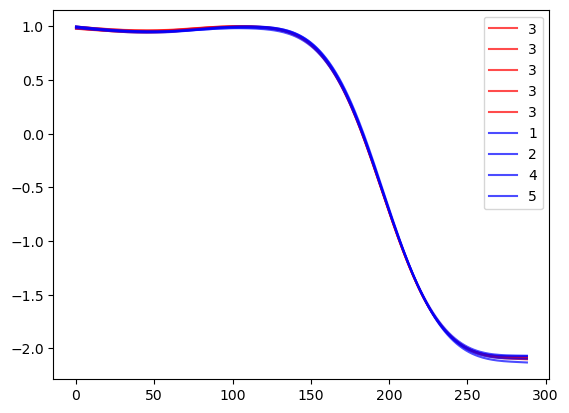

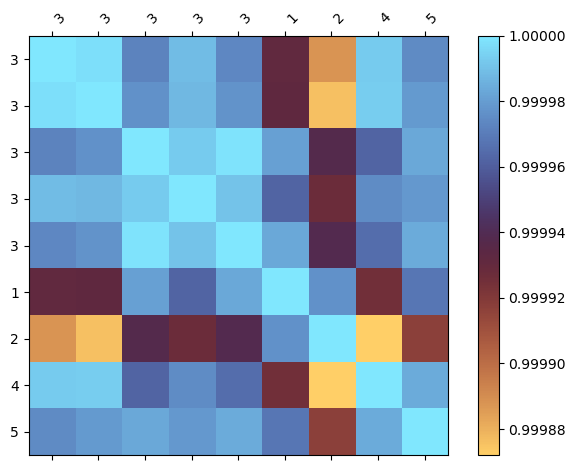

In [10]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(str(trace['info']['serial']))
        
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for i, (x, lab) in enumerate(zip(deltas, labels)):
        ax.plot(x, label=lab, color=('red' if i<len(group_a) else 'blue'), alpha=0.7)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
#plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', smooth=1e-2)

Baseline threshold set at 0.970044
Within class: 0.981±0.0138 min: 0.969 max: 1
Cross class: 0.97±0.00108 min: 0.968 max: 0.972
Baseline false negative probability: 0.223542238074
Baseline false positive probability: 0.346638143792


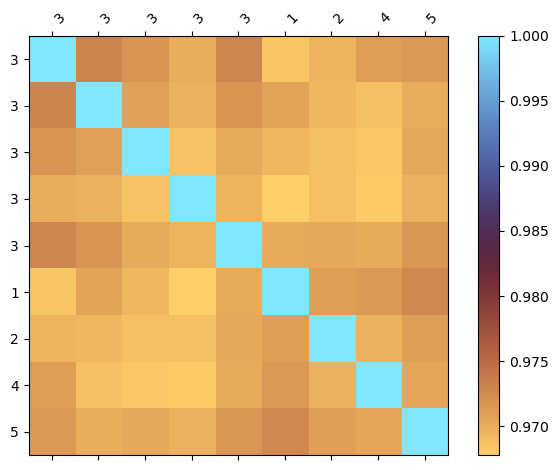

In [11]:
def plot_vector_covar(group_a, group_b, do_cal=False, vector_method='norm', distance_method='corr', smooth=None):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['serial'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
                
            if smooth is not None:
                t = np.linspace(0, 1, len(trace_data))
                spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
                trace_data = spl(t)
            
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        if distance_method == 'corr':
            corr[i] = np.corrcoef(deltas[:,i,:])
        elif distance_method == 'max':
            for k, l in itertools.product(range(len(all_traces)), repeat=2):
                corr[i, k, l] = 1 - np.abs(deltas[k,i,:] - deltas[l,i,:]).max()
        else:
            raise ValueError(f'invalid distance_method {distance_method!r}')

    if vector_method == 'norm':
        corr = np.sqrt(np.mean(np.square(corr), axis=0))
    elif vector_method == 'min':
        corr = np.min(corr, axis=0)
    else:
        raise ValueError(f'invalid vector_method {vector_method!r}')
    
    within_class = corr[:len(group_a), :len(group_a)][np.triu_indices(len(group_a))]
    cross_class = corr[len(group_a):, :len(group_a)].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    #threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    threshold = (np.min(within_class) + np.max(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} min: {np.min(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b, distance_method='corr', smooth=None)

## Can we distinguish one specimen from other specimens with the same layout?

Baseline threshold set at 0.970219
Within class: 0.98±0.0143 min: 0.968 max: 1
Cross class: 0.969±0.00174 min: 0.966 max: 0.973
Baseline false negative probability: 0.250905313012
Baseline false positive probability: 0.216360494616


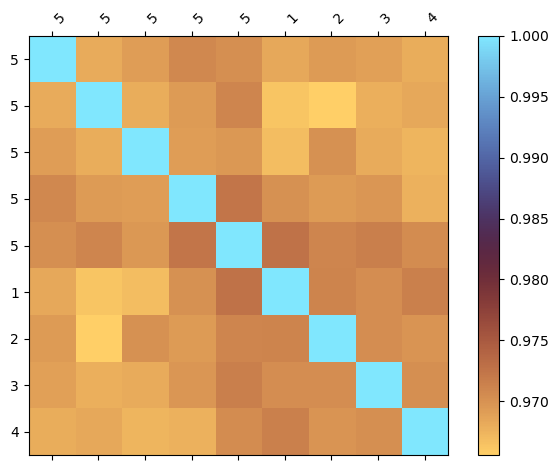

In [12]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0005-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1234]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b)

## Can we distinguish mesh layout variants?

Compare measurements of five specimens of the base layout against measurements of each of the four alternate layouts.

Baseline threshold set at 0.959400
Within class: 0.981±0.0138 min: 0.97 max: 1
Cross class: 0.918±0.0392 min: 0.85 max: 0.949
Baseline false negative probability: 0.061786123565
Baseline false positive probability: 0.143791257829


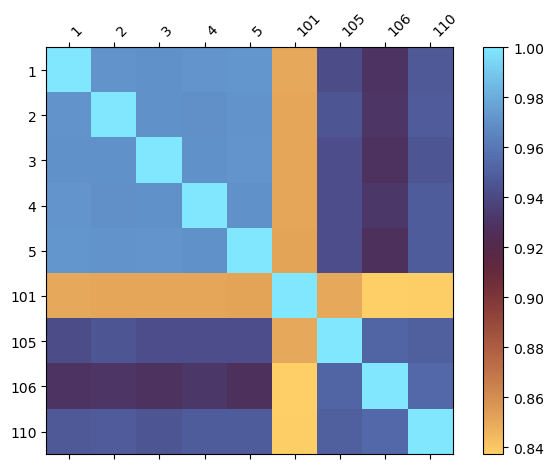

In [13]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b)

#### Same measurement, but show TPD0604 data 

Baseline threshold set at 0.995603
Within class: 0.998±0.00148 min: 0.996 max: 1
Cross class: 0.98±0.0243 min: 0.935 max: 0.995
Baseline false negative probability: 0.057732685452
Baseline false positive probability: 0.255665958633


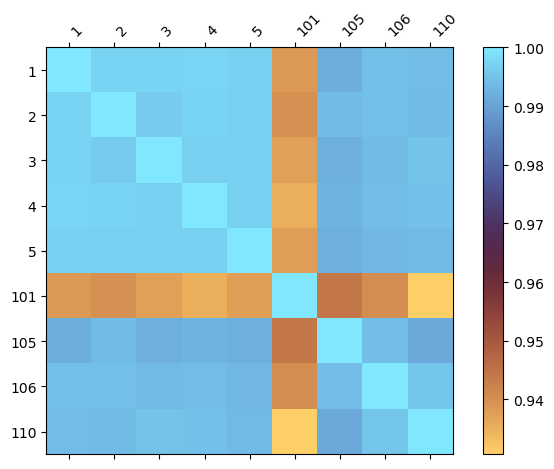

In [14]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)

Baseline threshold set at 0.799796
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.564±0.031 min: 0.52 max: 0.621
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


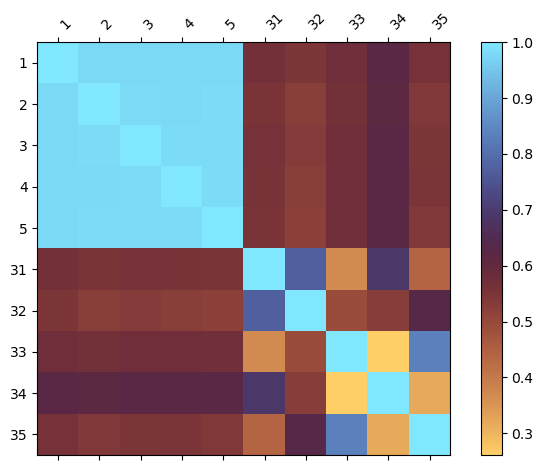

In [15]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.3])

Baseline threshold set at 0.734041
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.431±0.0412 min: 0.365 max: 0.489
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


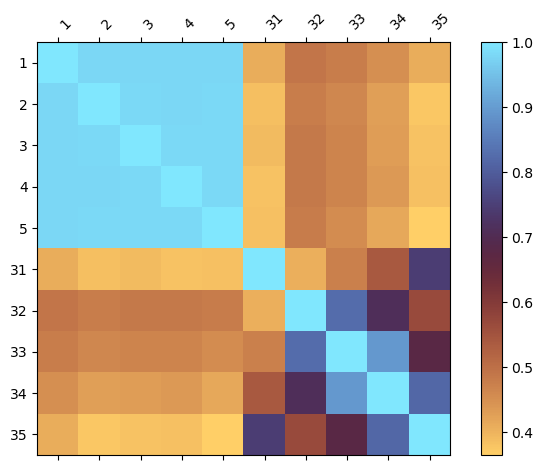

In [16]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.4])

Baseline threshold set at 0.676569
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.325±0.0387 min: 0.256 max: 0.374
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


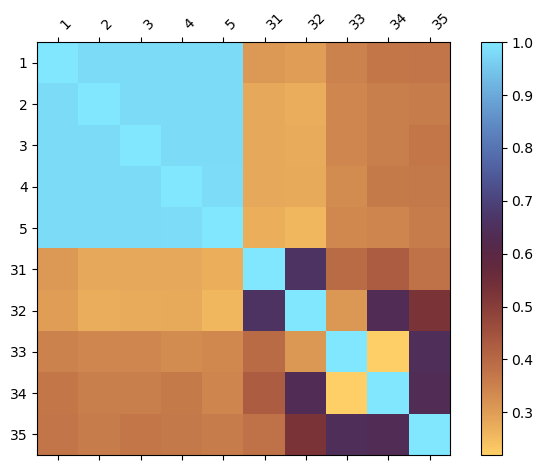

In [17]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.6])

Baseline threshold set at 0.621972
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.195±0.0324 min: 0.164 max: 0.265
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


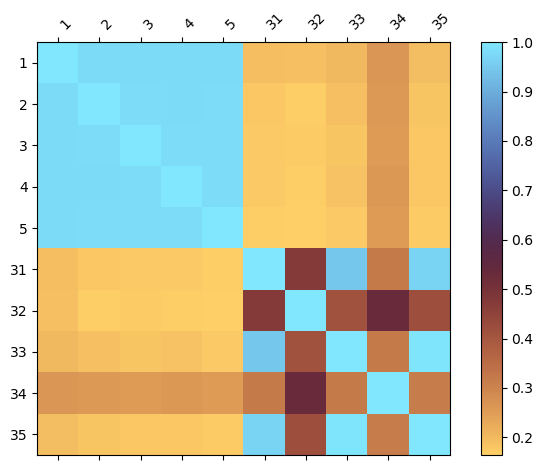

In [18]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 1.0])

Baseline threshold set at 0.873177
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.724±0.0306 min: 0.673 max: 0.767
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000588636


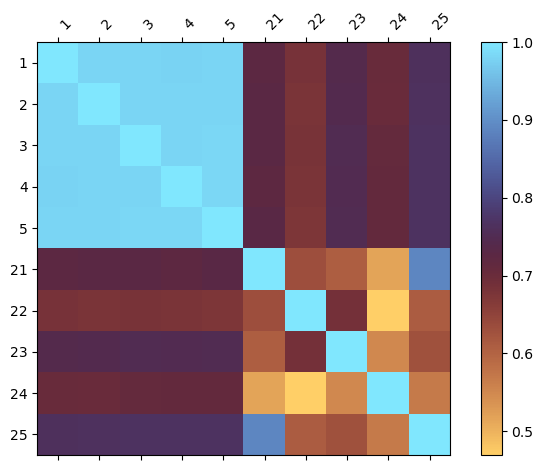

In [19]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.3])

Baseline threshold set at 0.776802
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.55±0.0219 min: 0.507 max: 0.575
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


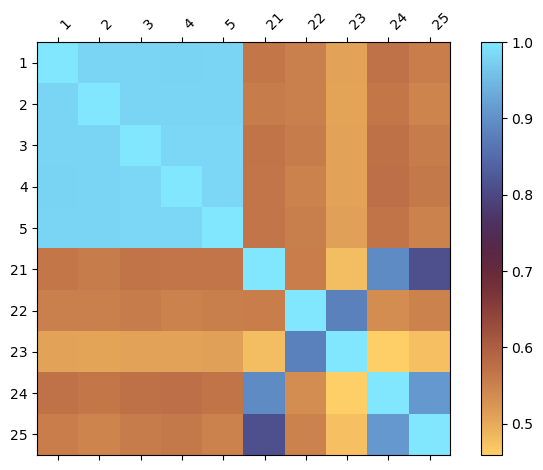

In [20]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.4])

Baseline threshold set at 0.763218
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.382±0.0896 min: 0.285 max: 0.548
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000010264700


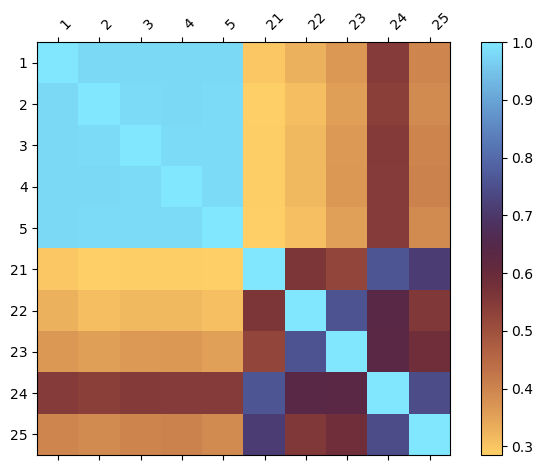

In [21]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.6])

Baseline threshold set at 0.722767
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.279±0.0854 min: 0.212 max: 0.467
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000102298


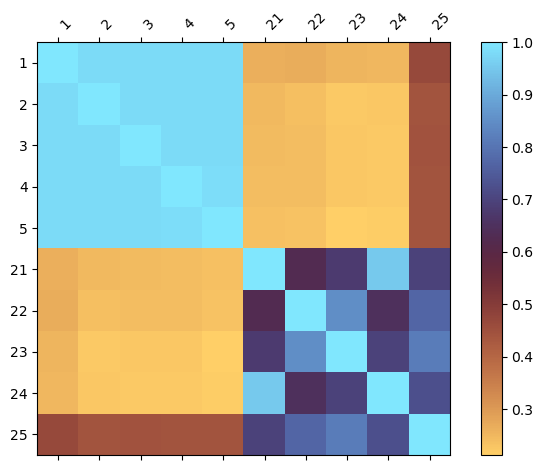

In [22]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 1.0])

Baseline threshold set at 0.998915
Within class: 0.999±0.000497 min: 0.999 max: 1
Cross class: 0.968±0.0572 min: 0.852 max: 0.999
Baseline false negative probability: 0.183174931225
Baseline false positive probability: 0.292244422722


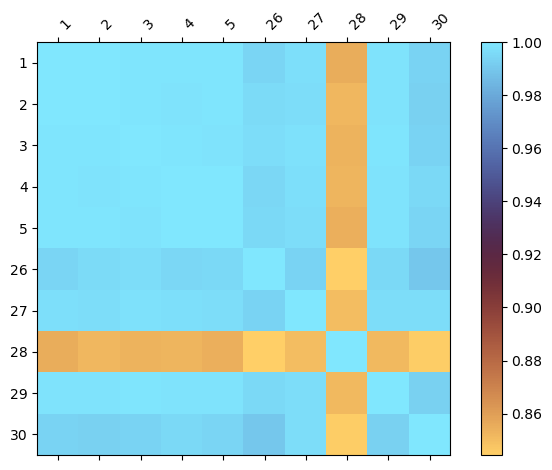

In [23]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], distance_method='corr', vector_method='norm', smooth=1e-5)

Baseline threshold set at 0.965977
Within class: 0.999±0.000931 max: 1
Cross class: 0.933±0.147 max: 1
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.410497896088


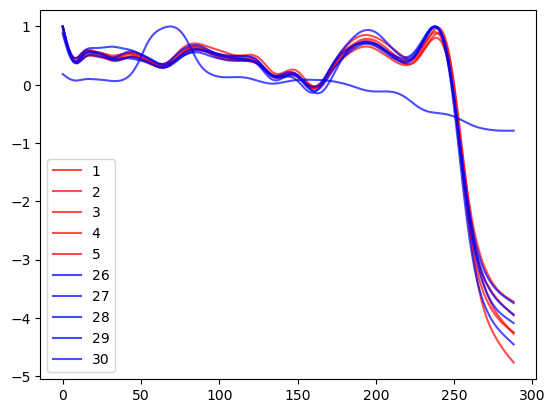

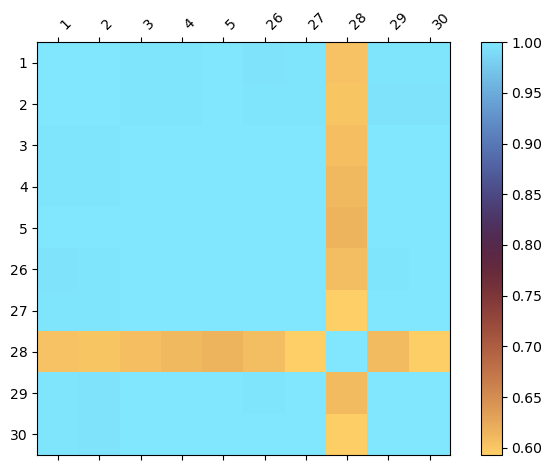

In [24]:
plot_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], select_trace='open_fwd', select_channel='adc1', smooth=1e-5)

Baseline threshold set at 0.839677
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.634±0.0624 min: 0.517 max: 0.7
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000480319610


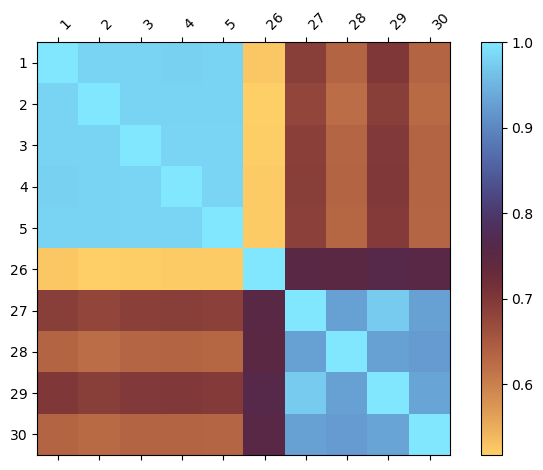

In [25]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.4])

Baseline threshold set at 0.665747
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.343±0.00806 min: 0.324 max: 0.353
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


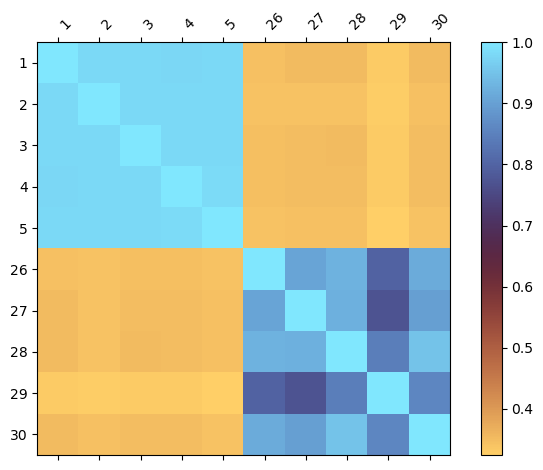

In [26]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.6])

Baseline threshold set at 0.645771
Within class: 0.987±0.00931 min: 0.979 max: 1
Cross class: 0.271±0.0195 min: 0.238 max: 0.313
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


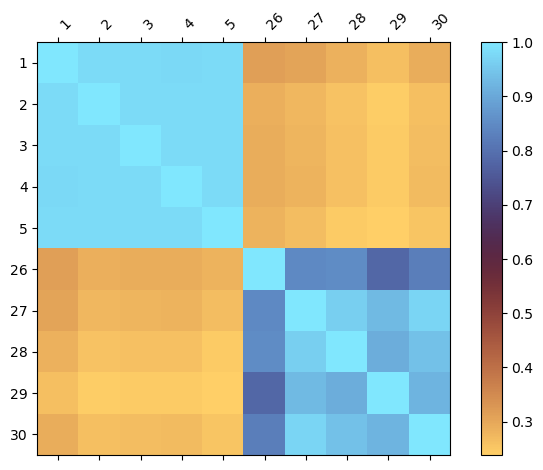

In [27]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 1.0])

Baseline threshold set at 0.997162
Within class: 0.998±0.00118 min: 0.996 max: 1
Cross class: 0.916±0.109 min: 0.703 max: 0.999
Baseline false negative probability: 0.205281062771
Baseline false positive probability: 0.225991265055
Baseline threshold set at 0.988713
Within class: 0.993±0.00437 min: 0.984 max: 1
Cross class: 0.637±0.421 min: -0.132 max: 0.993
Baseline false negative probability: 0.168953599799
Baseline false positive probability: 0.201880951411
Baseline threshold set at 0.979558
Within class: 0.911±0.0498 min: 0.828 max: 1
Cross class: 0.904±0.109 min: 0.739 max: 1.13
Baseline false negative probability: 0.917112633703
Baseline false positive probability: 0.243017028558
Baseline threshold set at 0.484125
Within class: 0.672±0.194 min: 0.252 max: 1
Cross class: -0.882±1.38 min: -3.02 max: 0.716
Baseline false negative probability: 0.166549069241
Baseline false positive probability: 0.160396017586


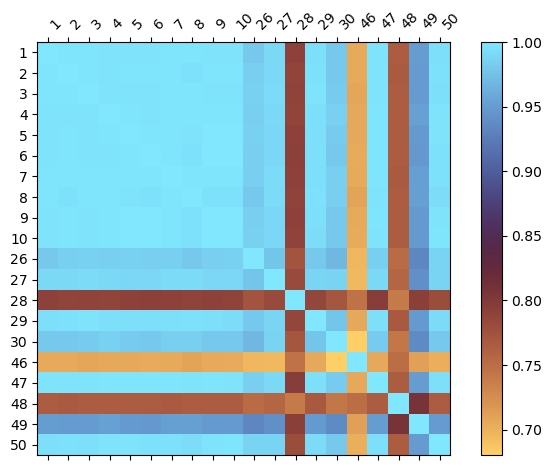

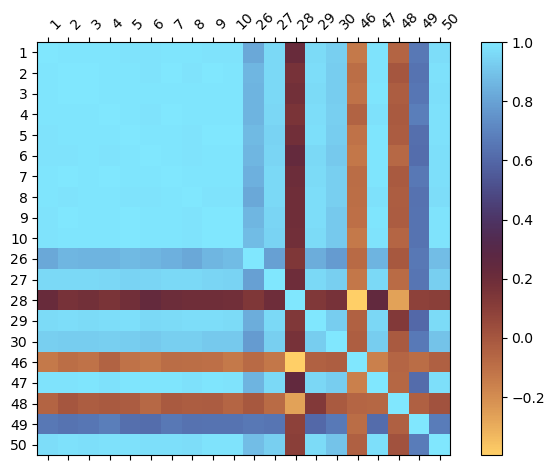

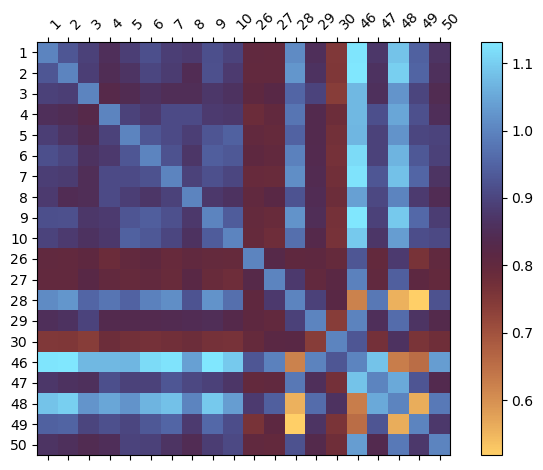

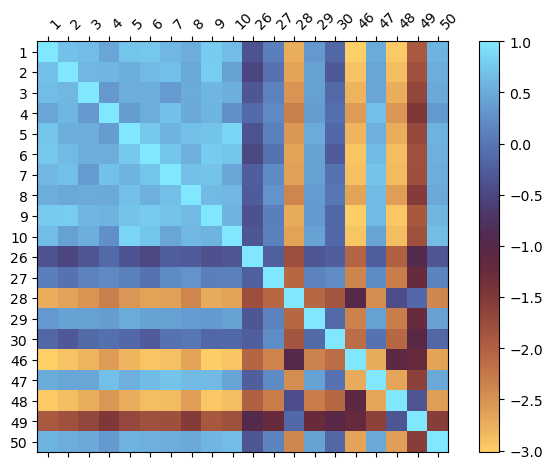

In [37]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = 1e-6
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth)